# 深度学习双任务标注 — 负面性 + 侮辱性

**数据**：`../Data/Human/Human_Result.csv`（420 条，人工 4 人标注的多数票，黄金标准）
**任务**：同一条评论上同时预测两个二分类标签
- `负面性标签`：是否负面
- `侮辱性标签`：是否含侮辱/攻击（正类仅 45 条 = 10.7%）

**层级约束**：业务规则「侮辱性 ⊆ 负面性」（骂人必是差评），本数据已验证 0 条违反。

## 建模路线总览

| 路线 | 输入 | 本 notebook |
|---|---|---|
| 传统 ML（SVM / LR / NB / RF） | TF-IDF 稀疏向量 | 见 `tfidf_features.ipynb` |
| LLM zero-shot / 提示词工程 | 原始评论文本 | 见 `llm_metrics.ipynb` |
| **深度学习（本 notebook）** | **字符序列 / 子词序列** | 共享编码器 + 两个 sigmoid 头 |

## 设计要点

| 要点 | 做法 | 为什么 |
|---|---|---|
| **不做任何"清洗"** | 只做 `strip`，保留标点、emoji、异体字 | 谐音（沙币）、拆字（歹匕）、形近字（出生→畜生）、符号替换（Fμ¢k）全部位于**字符层**，任何归一化都会摧毁这些对抗信号 |
| **同文分组切分** | `StratifiedGroupKFold(groups=归一化文本)` | 21 行短评文本重复（不同用户写出相同短评，属合法独立样本，**不去重**）；但同一文本跨训练/验证折会让指标虚高，所以切分时按文本分组。这是**评估协议**约束，不是数据清洗 |
| **双任务共享编码器** | `Loss = μ·BCE(负面性) + BCE(侮辱性)` | 两个标签高度相关（侮辱⇒负面），共享表征能互相借力；也避免训练两次 |
| **不平衡处理** | `pos_weight` 按类别频率反比开方 | 侮辱性正类只有 45 条，不加权则模型退化为"全判 0" |
| **阈值双报告** | 固定 0.5 与折内调优阈值分开列 | 在验证折上搜阈值偏乐观，混在一起会被审稿人抓 |
| **`类型` 列不作输入** | 只用于分层与误差分析 | 否则就是把答案喂给模型（`类型` 本身就编码了是否有侮辱） |

## 两种后端（本 notebook 默认零依赖后端）

| 后端 | 说明 |
|---|---|
| `char`（默认，本 notebook 跑的就是它） | 纯 PyTorch：Embedding → BiGRU / TextCNN → 注意力池化。**不需要下载任何模型** |
| `hf` | 微调中文预训练模型（`hfl/chinese-roberta-wwm-ext`），把 `USE_HF` 改成 `True` 即可。需要能访问 HuggingFace（或设 `HF_ENDPOINT=https://hf-mirror.com`，或用本地目录） |

## 输出
`../Data/DL/` 下：OOF 预测表（列名与 `ML_predictions.csv` 对齐）、主结果表、每折指标、分类型细分、混淆矩阵、常数基线、阈值记录、图。

In [1]:
# ============ 环境与全局配置 / Environment & global config ============
import hashlib
import json
import math
import os
import random
import re
import time
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore")

# 路径：兼容「在 scripts/ 下执行」与「在仓库根执行」两种情形
# Paths: works whether the kernel runs in scripts/ or in the repo root.
CWD = Path.cwd()
PROJ = CWD.parent if CWD.name == "scripts" else CWD
DATA_PATH = PROJ / "Data" / "Human" / "Human_Result.csv"
RAW_VOTES = PROJ / "Data" / "Human" / "Human.csv"
OUT_DIR = PROJ / "Data" / "DL"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DIMS = ("负面性", "侮辱性")                     # 两个任务头 / two task heads
LABEL_COLS = {d: f"{d}标签" for d in DIMS}
TYPE_ORDER = ["好评", "正常差评", "语气型差评", "声音型差评", "视觉型差评"]

# ---------------- 超参数 / Hyper-parameters ----------------
SEED = 42
N_FOLDS = 5
EPOCHS = 30
PATIENCE = 5
BATCH_SIZE = 16
DROPOUT = 0.3
EMB_DIM = 128
HIDDEN_DIM = 128
MAXLEN = 128
ARCH = "gru"                 # gru | bilstm | cnn
POS_WEIGHT = "sqrt"          # none | ratio | sqrt
FOCAL_GAMMA = 0.0            # >0 启用 Focal Loss
NEG_LOSS_WEIGHT = 1.0        # 负面性头的损失权重 μ
SELECT_METRIC = "both_macro" # 早停依据：both_macro | insult_f1 | neg_f1
THRESHOLD_METRIC = "f1"      # 折内阈值搜索目标：f1 | f2
N_BOOT = 1000
GROUP_BY_TEXT = True         # 按文本分组切分（防同文跨折泄漏）
HIERARCHY_FIX = True         # 侮辱 ⇒ 负面 后处理

USE_HF = False               # True 则用预训练模型（需可访问 HF）
HF_MODEL = "hfl/chinese-roberta-wwm-ext"
LR = 2e-5 if USE_HF else 1e-3

# 后端选择：USE_HF 且模型可取到才用 hf，否则回落 char
os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "5")
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "20")

def _hf_ready():
    if not USE_HF:
        return False, "USE_HF=False"
    try:
        from transformers import AutoConfig
        AutoConfig.from_pretrained(HF_MODEL)
        return True, "ok"
    except Exception as e:
        return False, f"{type(e).__name__}"

BACKBONE_OK, _why = _hf_ready()
BACKBONE = "hf" if BACKBONE_OK else "char"

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    try:
        torch.mps.manual_seed(seed)
    except Exception:
        pass

set_seed()

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"torch {torch.__version__} | 设备 device = {DEVICE}")
print(f"后端 backbone = {BACKBONE}" + ("" if BACKBONE_OK else f"（预训练不可用：{_why}）"))
print(f"数据 data = {DATA_PATH}")

torch 2.8.0 | 设备 device = mps
后端 backbone = char（预训练不可用：USE_HF=False）
数据 data = /Users/Edward/Github/LLM-Sentiment-Analysis/Data/Human/Human_Result.csv


## 一、数据体检

先确认三件事，再谈建模：
1. **标签是否合法**（只允许 0/1）
2. **层级约束**（侮辱 ⇒ 负面）是否被违反
3. **与原始 4 人投票表是否逐行对齐**、多数票能否复现（证明结果列不是手改的）

顺便统计重复文本：这些是**不同用户写出的相同短评**，属于合法独立样本，**不做去重**，只影响切分时的分组键。

In [2]:
def norm_key(text: str) -> str:
    """归一化文本，仅用于分组切分，不参与建模。
    Normalize for grouping only — never used as model input."""
    s = unicodedata.normalize("NFKC", str(text))
    return re.sub(r"[^\w\u4e00-\u9fff]+", "", s.lower())


def md5_of(path: Path) -> str:
    return hashlib.md5(path.read_bytes()).hexdigest()


df = pd.read_csv(DATA_PATH)
texts = df["评论"].astype(str).str.strip().tolist()
Y = df[[LABEL_COLS[d] for d in DIMS]].to_numpy(dtype=np.float32)
groups = np.array([norm_key(t) for t in texts], dtype=object)
# 分层键：两标签的联合类别，保证每折都含侮辱性正例
STRAT = (Y[:, 0].astype(int) * 2 + Y[:, 1].astype(int))

assert np.isin(Y, [0, 1]).all(), "标签存在非 0/1 取值"
viol = int(((Y[:, 1] == 1) & (Y[:, 0] == 0)).sum())
dup_rows = int(pd.Series(groups).duplicated(keep=False).sum())
n_unique = len(pd.unique(pd.Series(groups)))

# 与原始投票表复核 / cross-check against the raw 4-annotator votes
raw = pd.read_csv(RAW_VOTES)
assert (raw["评论"].astype(str).str.strip() == df["评论"].astype(str).str.strip()).all(), "两表未逐行对齐"
vote_report = {}
for d in DIMS:
    cols = [f"{d}{i}" for i in range(1, 5)]
    maj = (raw[cols].mean(axis=1) >= 0.5).astype(int).to_numpy()
    vote_report[d] = int((maj == df[LABEL_COLS[d]].to_numpy()).sum())

print("=" * 72)
print(f"样本数 rows                  : {len(df)}")
for k, d in enumerate(DIMS):
    n_pos = int(Y[:, k].sum())
    print(f"{d} 正类 positives      : {n_pos} ({n_pos / len(df):.1%})")
print(f"层级约束违反 hierarchy viol   : {viol}")
print(f"重复文本行 duplicated rows    : {dup_rows}（唯一文本 {n_unique} 条）")
print(f"多数票复现 majority vote      : "
      + "，".join(f"{d} {v}/{len(df)}" for d, v in vote_report.items()))
print(f"数据指纹 md5                  : {md5_of(DATA_PATH)[:16]}...")
print("=" * 72)
print("\n各组合类别分布 / joint class distribution:")
print(pd.crosstab(df["类型"], [df["负面性标签"], df["侮辱性标签"]]))

样本数 rows                  : 420
负面性 正类 positives      : 236 (56.2%)
侮辱性 正类 positives      : 45 (10.7%)
层级约束违反 hierarchy viol   : 0
重复文本行 duplicated rows    : 21（唯一文本 406 条）
多数票复现 majority vote      : 负面性 420/420，侮辱性 417/420
数据指纹 md5                  : dbb563ba66a9de99...

各组合类别分布 / joint class distribution:
负面性标签    0    1    
侮辱性标签    0    0   1
类型                 
声音型差评    0    8  22
好评     182    0   0
正常差评     2  112   0
视觉型差评    0    4  17
语气型差评    0   67   6


## 二、文本编码

**字符级**（默认后端）：按字符建词表，标点、emoji、异体字全部保留。
词表**只在训练折上**构建，避免验证折信息泄漏。

**子词级**（`USE_HF=True` 时）：直接用中文预训练模型自带的词表，
全字符覆盖，同样不做任何自定义清洗。

In [3]:
class CharVocabEncoder:
    """字符级编码器。Char-level encoder keeping every character."""

    PAD, UNK = 0, 1

    def __init__(self, maxlen=MAXLEN):
        self.maxlen = maxlen
        self.vocab = {}

    def fit(self, texts):
        chars = sorted({c for t in texts for c in t})
        self.vocab = {c: i + 2 for i, c in enumerate(chars)}
        return self

    @property
    def vocab_size(self):
        return len(self.vocab) + 2

    def encode_batch(self, texts):
        ids = np.zeros((len(texts), self.maxlen), dtype=np.int64)
        mask = np.zeros((len(texts), self.maxlen), dtype=np.int64)
        for i, t in enumerate(texts):
            seq = [self.vocab.get(c, self.UNK) for c in t[: self.maxlen]]
            ids[i, : len(seq)] = seq
            mask[i, : len(seq)] = 1
            if not seq:
                mask[i, 0] = 1                      # 空串兜底，避免全 padding
        return {"input_ids": torch.from_numpy(ids),
                "attention_mask": torch.from_numpy(mask)}


class HfTextEncoder:
    """HF 分词器封装（词表固定，不做自定义清洗）。"""

    def __init__(self, model_name=HF_MODEL, maxlen=MAXLEN):
        from transformers import AutoTokenizer
        self.maxlen = maxlen
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)

    def fit(self, texts):
        return self

    def encode_batch(self, texts):
        enc = self.tokenizer(list(texts), padding=True, truncation=True,
                             max_length=self.maxlen, return_tensors="pt")
        return {k: v for k, v in enc.items()
                if k in ("input_ids", "attention_mask", "token_type_ids")}


print("编码器类已定义 / encoders defined")

编码器类已定义 / encoders defined


## 三、模型结构

**共享编码器 + 两个独立 sigmoid 头**。字符级编码器有两种可选结构：

- `gru`（默认）：BiGRU + 掩码注意力池化 —— 能保留字序，对"由…到…"这类反讽句式有优势
- `cnn`：2/3/4-gram 多尺度卷积 —— 擅长抓 `沙币`、`歹匕` 这种 2~4 字的局部替换模式

注意力池化会在长评论里自动把权重压到关键片段上。

In [4]:
class AttentionPool(nn.Module):
    """掩码加性注意力池化。Masked additive attention pooling."""

    def __init__(self, dim):
        super().__init__()
        self.score = nn.Linear(dim, 1)

    def forward(self, h, mask):
        s = self.score(h).squeeze(-1)
        s = s.masked_fill(mask == 0, -1e4)          # 屏蔽 padding
        a = torch.softmax(s, dim=-1)
        return torch.einsum("bl,blh->bh", a, h)


class CharEncoder(nn.Module):
    """字符级编码器：Embedding → BiGRU / TextCNN → 池化。"""

    def __init__(self, vocab_size, emb_dim=EMB_DIM, hidden_dim=HIDDEN_DIM,
                 arch=ARCH, dropout=DROPOUT, pad_id=0):
        super().__init__()
        self.arch = arch
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)
        self.drop = nn.Dropout(dropout)
        if arch == "cnn":
            self.convs = nn.ModuleList(
                [nn.Conv1d(emb_dim, hidden_dim // 3 + 1, k) for k in (2, 3, 4)])
            out_dim = sum(c.out_channels for c in self.convs)
        else:
            rnn = nn.GRU if arch == "gru" else nn.LSTM
            self.rnn = rnn(emb_dim, hidden_dim // 2, batch_first=True,
                           bidirectional=True)
            self.pool = AttentionPool(hidden_dim)
            out_dim = hidden_dim
        self.out_dim = out_dim

    def forward(self, input_ids, attention_mask, **_):
        x = self.drop(self.emb(input_ids))
        if self.arch == "cnn":
            feats = [F.relu(c(x.transpose(1, 2))).max(dim=-1).values
                     for c in self.convs]
            return self.drop(torch.cat(feats, dim=-1))
        out, _ = self.rnn(x)
        out = out * attention_mask.unsqueeze(-1).to(out.dtype)
        return self.drop(self.pool(out, attention_mask))


class HfEncoder(nn.Module):
    """预训练 Transformer 主干 + 掩码平均池化。"""

    def __init__(self, model_name=HF_MODEL):
        super().__init__()
        from transformers import AutoConfig, AutoModel
        self.cfg = AutoConfig.from_pretrained(model_name)
        self.body = AutoModel.from_pretrained(model_name)
        self.out_dim = int(getattr(self.cfg, "hidden_size", 768))

    def forward(self, input_ids, attention_mask, token_type_ids=None, **_):
        kw = {"input_ids": input_ids, "attention_mask": attention_mask}
        if token_type_ids is not None:
            kw["token_type_ids"] = token_type_ids
        h = self.body(**kw).last_hidden_state
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        return (h * m).sum(1) / m.sum(1).clamp(min=1e-6)


class MultiTaskNet(nn.Module):
    """共享编码器 + 两个 sigmoid 头。Shared encoder + two sigmoid heads."""

    def __init__(self, encoder, dropout=DROPOUT, n_tasks=2):
        super().__init__()
        self.encoder = encoder
        self.drop = nn.Dropout(dropout)
        self.heads = nn.ModuleList([nn.Linear(encoder.out_dim, 1)
                                    for _ in range(n_tasks)])

    def forward(self, input_ids=None, attention_mask=None, token_type_ids=None, **_):
        h = self.drop(self.encoder(input_ids=input_ids,
                                   attention_mask=attention_mask,
                                   token_type_ids=token_type_ids))
        return torch.cat([head(h) for head in self.heads], dim=-1)


def build_encoder(texts_tr):
    if BACKBONE == "hf":
        return HfTextEncoder(HF_MODEL).fit(texts_tr)
    return CharVocabEncoder().fit(texts_tr)


def build_model(encoder):
    if BACKBONE == "hf":
        return MultiTaskNet(HfEncoder(HF_MODEL))
    return MultiTaskNet(CharEncoder(encoder.vocab_size))

n_params = sum(p.numel() for p in build_model(build_encoder(texts[:8])).parameters())
print(f"模型类已定义 / model classes defined（单折参数量约 {n_params:,}）")

模型类已定义 / model classes defined（单折参数量约 98,947）


## 四、损失、指标与阈值

**损失**：两任务各建一个 `BCEWithLogitsLoss`，`pos_weight` 按类别频率反比（开方压缩）。
侮辱性正类只有 10.7%，不加权模型会直接退化成"全判 0"。可选 `FOCAL_GAMMA > 0` 启用 Focal Loss。

**指标**：正类固定为 1，`Accuracy / Precision / Recall / F1 / Macro-F1`，`zero_division=0`
——与 `llm_metrics.ipynb`、`tfidf_features.ipynb` **完全同一口径**，这样三条路线的结果能进同一张表。

**阈值**：折内网格搜索最大化 F1；同时保留 0.5 的结果，避免"在验证折上调阈值"带来的乐观偏差被隐藏。

In [5]:
class FocalBCE(nn.Module):
    """Focal Loss 版 BCE（γ 越大越聚焦难样本）。"""

    def __init__(self, gamma=2.0, pos_weight=None):
        super().__init__()
        self.gamma = gamma
        self.register_buffer("pos_weight", pos_weight)

    def forward(self, logits, targets):
        p = torch.sigmoid(logits)
        ce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none",
                                                pos_weight=self.pos_weight)
        p_t = p * targets + (1 - p) * (1 - targets)
        return ((1 - p_t) ** self.gamma * ce).mean()


def make_criteria(y_tr, device):
    """每个任务头一个损失函数：pos_weight 必须按头切开（[2] 直接传会维度不匹配）。"""
    if POS_WEIGHT == "none":
        pw = None
    else:
        n_pos = y_tr.sum(axis=0)
        w = (len(y_tr) - n_pos) / np.clip(n_pos, 1, None)
        pw = torch.tensor(np.sqrt(w) if POS_WEIGHT == "sqrt" else w,
                          dtype=torch.float32)
    crit = []
    for k in range(2):
        wk = None if pw is None else pw[k:k + 1].to(device)
        crit.append(FocalBCE(FOCAL_GAMMA, wk).to(device) if FOCAL_GAMMA > 0
                    else nn.BCEWithLogitsLoss(pos_weight=wk))
    return crit


def compute_metrics(y_true, y_pred):
    """与既有 LLM / TF-IDF 实验同口径的五个指标。"""
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "MacroF1": f1_score(y_true, y_pred, average="macro", zero_division=0)}


def best_threshold(y_true, prob, metric=THRESHOLD_METRIC):
    """在验证折上网格搜索最优阈值（偏乐观，故与 0.5 结果并列报告）。"""
    best_t, best_s = 0.5, -1.0
    for t in np.arange(0.05, 1.0, 0.05):
        pred = (prob >= t).astype(int)
        if metric == "f2":
            p = precision_score(y_true, pred, zero_division=0)
            r = recall_score(y_true, pred, zero_division=0)
            s = 0.0 if (p + r) == 0 else 5 * p * r / (4 * p + r)
        else:
            s = f1_score(y_true, pred, zero_division=0)
        if s > best_s:
            best_t, best_s = float(t), float(s)
    return best_t


def bootstrap_ci(y_true, y_pred, n_boot=N_BOOT, alpha=0.05, seed=SEED):
    """池化 OOF 上的 Bootstrap 95% 置信区间。"""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    acc = {k: [] for k in ["Accuracy", "Precision", "Recall", "F1", "MacroF1"]}
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y_true[idx].sum() == 0:
            continue
        m = compute_metrics(y_true[idx], y_pred[idx])
        for k in acc:
            acc[k].append(m[k])
    return {k: (float(np.percentile(v, 100 * alpha / 2)),
                float(np.percentile(v, 100 * (1 - alpha / 2))))
            for k, v in acc.items()}


print("损失与指标工具已定义 / losses & metrics defined")

损失与指标工具已定义 / losses & metrics defined


## 五、训练

单折流程：建词表 → 训练 → 每轮在验证折评估 → 早停保存最佳轮 → 用最佳轮预测验证折。

**早停依据** `both_macro`：两个标签 F1 的均值。也可以改成 `insult_f1` 专门盯侮辱性
（正类少、波动大，专盯它会让早停很不稳定，所以默认为两任务均值）。

优化器 `AdamW` + `OneCycleLR` + 梯度裁剪 1.0，小数据短训练下这个组合最稳。

In [6]:
class CommentDataset(Dataset):
    """只存文本与标签，编码交给 collate（便于 HF tokenizer 批量处理）。"""

    def __init__(self, texts, labels):
        self.texts, self.labels = list(texts), torch.from_numpy(
            np.asarray(labels, dtype=np.float32))

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        return self.texts[i], self.labels[i]


def make_loader(texts, labels, encoder, shuffle, generator=None):
    def collate(batch):
        txts, labs = zip(*batch)
        enc = encoder.encode_batch(list(txts))
        enc["labels"] = torch.stack(labs)
        return enc
    return DataLoader(CommentDataset(texts, labels), batch_size=BATCH_SIZE,
                      shuffle=shuffle, collate_fn=collate, num_workers=0,
                      generator=generator)


@torch.no_grad()
def predict_probs(model, loader, device):
    model.eval()
    out = []
    for batch in loader:
        x = {k: v.to(device) for k, v in batch.items() if k != "labels"}
        out.append(torch.sigmoid(model(**x)).float().cpu().numpy())
    return np.concatenate(out, axis=0)


def train_fold(texts_tr, y_tr, texts_va, y_va, fold, device, verbose=True):
    """训练一折，返回验证折概率与训练记录。"""
    t0 = time.time()
    # 每折入口按折号播种：该折结果完全由 (SEED, fold) 决定，
    # 与之前执行过什么 cell / 消费过多少随机数无关。
    # Seed per fold so the fold is fully determined by (SEED, fold),
    # independent of anything executed before.
    set_seed(SEED + fold)
    encoder = build_encoder(texts_tr)
    model = build_model(encoder).to(device)
    criteria = make_criteria(y_tr, device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    steps = max(1, math.ceil(len(texts_tr) / BATCH_SIZE)) * EPOCHS
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR,
                                                total_steps=steps, pct_start=0.15)
    tr_loader = make_loader(texts_tr, y_tr, encoder, True,
                            torch.Generator().manual_seed(SEED + fold))
    va_loader = make_loader(texts_va, y_va, encoder, False)

    hist = {"epoch": [], "train_loss": [], "f1_neg": [], "f1_ins": []}
    best = {"score": -1.0, "epoch": -1, "probs": None}

    for ep in range(1, EPOCHS + 1):
        model.train()
        tot, nb = 0.0, 0
        for batch in tr_loader:
            labels = batch.pop("labels").to(device)
            x = {k: v.to(device) for k, v in batch.items()}
            logits = model(**x)
            # 双任务联合损失 / joint multi-task loss
            loss = (criteria[0](logits[:, 0], labels[:, 0]) * NEG_LOSS_WEIGHT
                    + criteria[1](logits[:, 1], labels[:, 1]))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            tot += float(loss); nb += 1

        probs = predict_probs(model, va_loader, device)
        f1s = [f1_score(y_va[:, k], (probs[:, k] >= 0.5).astype(int), zero_division=0)
               for k in range(2)]
        sel = {"both_macro": float(np.mean(f1s)), "insult_f1": f1s[1],
               "neg_f1": f1s[0]}[SELECT_METRIC]

        hist["epoch"].append(ep); hist["train_loss"].append(tot / max(nb, 1))
        hist["f1_neg"].append(f1s[0]); hist["f1_ins"].append(f1s[1])
        if verbose:
            print(f"  fold{fold} ep{ep:>2}  loss={tot / max(nb, 1):.4f}  "
                  f"F1(负面)={f1s[0]:.4f}  F1(侮辱)={f1s[1]:.4f}  "
                  f"macro={np.mean(f1s):.4f}")

        if sel > best["score"] + 1e-6:
            best = {"score": sel, "epoch": ep, "probs": probs}
        elif ep - best["epoch"] >= PATIENCE:
            if verbose:
                print(f"  fold{fold} 早停 / early stop at ep{ep}（最佳 ep{best['epoch']}）")
            break

    thr = [best_threshold(y_va[:, k], best["probs"][:, k]) for k in range(2)]
    return best["probs"], {"fold": fold, "最佳轮次": best["epoch"],
                           "阈值_负面性": thr[0], "阈值_侮辱性": thr[1],
                           "耗时秒": round(time.time() - t0, 1), "hist": hist}


print("训练函数已定义 / training routine defined")

训练函数已定义 / training routine defined


## 六、5 折交叉验证（按文本分组）

**为什么必须分组**：`好吃` 出现 6 次、`可以`/`还可以`/`一般般` 各 3 次——
这些是不同用户写出的相同短评，**不去重**；但只要分散到训练折和验证折，
模型就是"见过原题"。所以用 `StratifiedGroupKFold(groups=归一化文本)`，
同一文本必落在同一折，同时按两标签联合类别分层，保证每折都有侮辱性正例。

In [7]:
# 关键：进入 CV 前重置一次随机种子。
# 前面「数字参数量」等 cell 会消耗全局随机流，不重置的话结果会随 cell 执行顺序漂移。
# Reset the RNG right before CV: earlier cells consume the global random stream,
# so without this the results drift with cell execution order.
set_seed(SEED)

y_all = Y
n = len(texts)
oof = np.zeros((n, 2), dtype=float)
fold_records = []

if GROUP_BY_TEXT:
    splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    splits = list(splitter.split(np.zeros(n), STRAT, groups=groups))
else:
    from sklearn.model_selection import StratifiedKFold
    splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    splits = list(splitter.split(np.zeros(n), STRAT))

print(f"{N_FOLDS} 折 CV | 后端 {BACKBONE} | 结构 {ARCH if BACKBONE == 'char' else HF_MODEL}")
print(f"分组切分 group_by_text = {GROUP_BY_TEXT} | 设备 {DEVICE}\n")

for fold, (itr, iva) in enumerate(splits, start=1):
    probs, rec = train_fold([texts[i] for i in itr], y_all[itr],
                            [texts[i] for i in iva], y_all[iva],
                            fold, DEVICE)
    oof[iva] = probs
    yv = y_all[iva]
    for k, d in enumerate(DIMS):
        m05 = compute_metrics(yv[:, k], (probs[:, k] >= 0.5).astype(int))
        mt = compute_metrics(yv[:, k], (probs[:, k] >= rec["阈值_负面性" if k == 0 else "阈值_侮辱性"]).astype(int))
        rec.update({f"{d}_P@0.5": round(m05["Precision"], 4),
                    f"{d}_R@0.5": round(m05["Recall"], 4),
                    f"{d}_F1@0.5": round(m05["F1"], 4),
                    f"{d}_F1@调优": round(mt["F1"], 4)})
    rec["n_train"], rec["n_val"] = len(itr), len(iva)
    fold_records.append(rec)
    print(f"  → fold{fold} 完成 | 阈值 负面={rec['阈值_负面性']:.2f} "
          f"侮辱={rec['阈值_侮辱性']:.2f} | F1(负面)={rec['负面性_F1@0.5']:.4f} "
          f"F1(侮辱)={rec['侮辱性_F1@0.5']:.4f} | {rec['耗时秒']}s\n")

fold_df = pd.DataFrame(fold_records)
# 层级修正：侮辱 ⇒ 负面 / hierarchy post-processing
oof_fix = oof.copy()
n_fixed = int(((oof[:, 1] >= 0.5) & (oof[:, 0] < 0.5)).sum())
oof_fix[(oof[:, 1] >= 0.5) & (oof[:, 0] < 0.5), 0] = 1.0
print(f"OOF 收集完成。层级修正 {n_fixed} 条（预测侮辱但未预测负面 → 修正为负面）")

5 折 CV | 后端 char | 结构 gru
分组切分 group_by_text = True | 设备 mps

  fold1 ep 1  loss=1.4413  F1(负面)=0.7229  F1(侮辱)=0.1538  macro=0.4384
  fold1 ep 2  loss=1.4014  F1(负面)=0.8352  F1(侮辱)=0.0000  macro=0.4176
  fold1 ep 3  loss=1.3050  F1(负面)=0.8539  F1(侮辱)=0.0000  macro=0.4270
  fold1 ep 4  loss=1.1779  F1(负面)=0.8095  F1(侮辱)=0.0000  macro=0.4048
  fold1 ep 5  loss=1.0433  F1(负面)=0.8372  F1(侮辱)=0.1818  macro=0.5095
  fold1 ep 6  loss=0.8935  F1(负面)=0.8537  F1(侮辱)=0.4615  macro=0.6576
  fold1 ep 7  loss=0.7303  F1(负面)=0.9111  F1(侮辱)=0.5000  macro=0.7056
  fold1 ep 8  loss=0.6288  F1(负面)=0.9348  F1(侮辱)=0.4615  macro=0.6982
  fold1 ep 9  loss=0.5239  F1(负面)=0.9053  F1(侮辱)=0.5000  macro=0.7026
  fold1 ep10  loss=0.4618  F1(负面)=0.9451  F1(侮辱)=0.4615  macro=0.7033
  fold1 ep11  loss=0.3385  F1(负面)=0.9545  F1(侮辱)=0.5714  macro=0.7630
  fold1 ep12  loss=0.2831  F1(负面)=0.9474  F1(侮辱)=0.4000  macro=0.6737
  fold1 ep13  loss=0.2166  F1(负面)=0.9278  F1(侮辱)=0.5000  macro=0.7139
  fold1 ep14  loss=0.2253  F

## 七、主结果

两套结果并列：
- **固定阈值 0.5**：部署时的默认阈值，是可信的主结果
- **折内调优阈值**：各折在自己验证集上搜出的阈值（取均值），**偏乐观**，仅作参考

In [8]:
mean_thr = fold_df[["阈值_负面性", "阈值_侮辱性"]].mean().to_numpy()
rows = []
for variant_id, variant in enumerate(["固定阈值0.5", "折内调优阈值"]):
    for k, d in enumerate(DIMS):
        t = 0.5 if variant_id == 0 else mean_thr[k]
        pred = (oof[:, k] >= t).astype(int)
        m = compute_metrics(y_all[:, k], pred)
        ci = bootstrap_ci(y_all[:, k], pred)
        row = {"维度": d, "阈值方案": variant, "阈值": round(float(t), 2)}
        row.update({kk: round(m[kk], 4) for kk in
                    ["Accuracy", "Precision", "Recall", "F1", "MacroF1"]})
        row["正类数"] = int(y_all[:, k].sum()); row["预测正类数"] = int(pred.sum())
        for kk in ["Accuracy", "Precision", "Recall", "F1", "MacroF1"]:
            row[f"{kk}_CI下限"], row[f"{kk}_CI上限"] = (round(ci[kk][0], 4), round(ci[kk][1], 4))
        rows.append(row)

if HIERARCHY_FIX and not np.array_equal(oof_fix, oof):
    pred = (oof_fix[:, 0] >= 0.5).astype(int)
    m, ci = compute_metrics(y_all[:, 0], pred), bootstrap_ci(y_all[:, 0], pred)
    row = {"维度": "负面性(层级修正)", "阈值方案": "固定阈值0.5", "阈值": 0.5}
    row.update({kk: round(m[kk], 4) for kk in
                ["Accuracy", "Precision", "Recall", "F1", "MacroF1"]})
    row["正类数"] = int(y_all[:, 0].sum()); row["预测正类数"] = int(pred.sum())
    for kk in ["Accuracy", "Precision", "Recall", "F1", "MacroF1"]:
        row[f"{kk}_CI下限"], row[f"{kk}_CI上限"] = (round(ci[kk][0], 4), round(ci[kk][1], 4))
    rows.append(row)

main_df = pd.DataFrame(rows)
tag = f"DL-{BACKBONE}" + (f"-{ARCH}" if BACKBONE == "char" else "")
print(f"【主结果 / Main results】{tag}  {N_FOLDS} 折 OOF\n")
print(main_df[["维度", "阈值方案", "Accuracy", "Precision", "Recall", "F1", "MacroF1"]].to_string(index=False))
print("\nF1 的 95% Bootstrap 置信区间：")
for r in main_df.itertuples():
    print(f"  {r.维度:<16s} {r.阈值方案:<10s} F1={r.F1:.4f}  [{r.F1_CI下限:.4f}, {r.F1_CI上限:.4f}]")

print("\n跨折波动 / cross-fold mean±std（侮辱性正类少，波动极大）:")
for c in ["负面性_F1@0.5", "侮辱性_F1@0.5", "负面性_F1@调优", "侮辱性_F1@调优"]:
    v = fold_df[c].to_numpy(dtype=float)
    print(f"  {c:<18s} {v.mean():.4f} ± {v.std(ddof=1):.4f}   (min {v.min():.4f} / max {v.max():.4f})")

【主结果 / Main results】DL-char-gru  5 折 OOF

 维度    阈值方案  Accuracy  Precision  Recall     F1  MacroF1
负面性 固定阈值0.5    0.8310     0.8287  0.8814 0.8542   0.8265
侮辱性 固定阈值0.5    0.8857     0.4706  0.5333 0.5000   0.7177
负面性  折内调优阈值    0.8048     0.7810  0.9068 0.8392   0.7954
侮辱性  折内调优阈值    0.7286     0.2326  0.6667 0.3448   0.5868

F1 的 95% Bootstrap 置信区间：
  负面性              固定阈值0.5    F1=0.8542  [0.8203, 0.8867]
  侮辱性              固定阈值0.5    F1=0.5000  [0.3711, 0.6154]
  负面性              折内调优阈值     F1=0.8392  [0.8054, 0.8701]
  侮辱性              折内调优阈值     F1=0.3448  [0.2541, 0.4353]

跨折波动 / cross-fold mean±std（侮辱性正类少，波动极大）:
  负面性_F1@0.5         0.8582 ± 0.0874   (min 0.7544 / max 0.9783)
  侮辱性_F1@0.5         0.5124 ± 0.1986   (min 0.1739 / max 0.7000)
  负面性_F1@调优          0.8831 ± 0.0807   (min 0.7544 / max 0.9783)
  侮辱性_F1@调优          0.5290 ± 0.2204   (min 0.1739 / max 0.7826)


## 八、误差分析

### 8.1 按 `类型` 细分

这是全文最值得看的一张表：模型在**语气型差评**（反讽、字面全是好话）上的侮辱性召回，
和它在**声音型**（谐音）、**视觉型**（拆字/符号）上的表现对比。

> 注意：某个组里如果只有一个类别（例如「好评」组根本没有侮辱性正类），
> 该组的 Precision / Recall / F1 在数学上无定义，表中**留空而不是记 0**，
> 否则会误导读者以为模型表现很差。

### 8.2 常数预测基线

正类只占 10.7% 时，「全判 0」的 Accuracy 高达 89% 但 F1 = 0。
把这张小表放进结果汇报，可以直接堵掉"为什么不用 Accuracy"的提问。

In [9]:
types = df["类型"].astype(str).to_numpy()
by_type_rows = []
for k, d in enumerate(DIMS):
    pred = (oof[:, k] >= 0.5).astype(int)
    for t in TYPE_ORDER:
        msk = types == t
        if msk.sum() == 0:
            continue
        yt, pt = y_all[msk, k], pred[msk]
        n_pos, n_neg = int(yt.sum()), int(len(yt) - yt.sum())
        tn, fp, fn, tp = confusion_matrix(yt, pt, labels=[0, 1]).ravel()
        row = {"维度": d, "类型": t, "n": int(msk.sum()), "正类数": n_pos,
               "误报FP": int(fp), "漏报FN": int(fn),
               "Accuracy": round(accuracy_score(yt, pt), 4)}
        if n_pos == 0 or n_neg == 0:
            row.update({"Precision": None, "Recall": None, "F1": None, "MacroF1": None})
        else:
            m = compute_metrics(yt, pt)
            row.update({kk: round(m[kk], 4) for kk in
                        ["Precision", "Recall", "F1", "MacroF1"]})
        by_type_rows.append(row)
by_type_df = pd.DataFrame(by_type_rows)

base_rows = []
for k, d in enumerate(DIMS):
    for name, const in [("全判0 / all-zero", 0), ("全判1 / all-one", 1)]:
        pred = np.full(n, const, dtype=int)
        base_rows.append({"维度": d, "基线": name, **{kk: round(compute_metrics(y_all[:, k], pred)[kk], 4)
                          for kk in ["Accuracy", "Precision", "Recall", "F1", "MacroF1"]}})
base_df = pd.DataFrame(base_rows)

conf_rows = []
for k, d in enumerate(DIMS):
    tn, fp, fn, tp = confusion_matrix(y_all[:, k], (oof[:, k] >= 0.5).astype(int),
                                      labels=[0, 1]).ravel()
    conf_rows.append({"维度": d, "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)})
conf_df = pd.DataFrame(conf_rows)

print("按类型细分（阈值 0.5）/ per-type breakdown:")
print(by_type_df.fillna("—").to_string(index=False))
print("\n常数预测基线 / degenerate baselines:")
print(base_df.to_string(index=False))
print("\n混淆矩阵（池化 OOF，阈值 0.5）:")
print(conf_df.to_string(index=False))

按类型细分（阈值 0.5）/ per-type breakdown:
 维度    类型   n  正类数  误报FP  漏报FN  Accuracy Precision  Recall      F1 MacroF1
负面性    好评 182    0    42     0    0.7692         —       —       —       —
负面性  正常差评 114  112     1    23    0.7895    0.9889  0.7946  0.8812  0.4791
负面性 语气型差评  73   73     0     4    0.9452         —       —       —       —
负面性 声音型差评  30   30     0     1    0.9667         —       —       —       —
负面性 视觉型差评  21   21     0     0    1.0000         —       —       —       —
侮辱性    好评 182    0     6     0    0.9670         —       —       —       —
侮辱性  正常差评 114    0     8     0    0.9298         —       —       —       —
侮辱性 语气型差评  73    6     9     4    0.8219    0.1818  0.3333  0.2353  0.5673
侮辱性 声音型差评  30   22     3     9    0.6000    0.8125  0.5909  0.6842  0.5694
侮辱性 视觉型差评  21   17     1     8    0.5714       0.9  0.5294  0.6667  0.5333

常数预测基线 / degenerate baselines:
 维度             基线  Accuracy  Precision  Recall     F1  MacroF1
负面性 全判0 / all-zero    0.4381     0.0000     

## 九、三方对比：深度学习 vs TF-IDF 机器学习 vs 大模型

同一批 420 条、同一套指标口径，把三条技术路线放进一张表。
这是结果汇报里最能说明"为什么要用大模型/深度学习"的那张表。

> **口径提醒**：DL 用的是**按文本分组**的 5 折 OOF（同文不跨折），
> TF-IDF 那批用的是普通分层 5 折（同一句 `好吃` 可能同时出现在训练与验证折，
> 因此它的数字可能略微偏乐观）。两者不完全同协议，严格对比时需要在正文里说明。

In [10]:
compare_rows = []

# ① 深度学习 / Deep learning
for k, d in enumerate(DIMS):
    pred = (oof_fix[:, k] >= 0.5).astype(int) if (k == 0 and HIERARCHY_FIX) else (oof[:, k] >= 0.5).astype(int)
    m = compute_metrics(y_all[:, k], pred)
    compare_rows.append({"路线": "深度学习 DL", "方法": tag, "维度": d,
                         **{kk: round(m[kk], 4) for kk in ["Accuracy", "Precision", "Recall", "F1"]}})

# ② TF-IDF 机器学习 / classical ML
ml_path = PROJ / "Data" / "ML" / "ML_predictions.csv"
if ml_path.exists():
    ml = pd.read_csv(ml_path)
    assert (ml["评论"].astype(str).str.strip()
            == df["评论"].astype(str).str.strip()).all(), "ML_predictions.csv 与标注表未逐行对齐"
    for col in ml.columns:
        if "+" not in col:
            continue
        algo, dim = col.split("+")
        k = 0 if dim.startswith("负面") else 1
        m = compute_metrics(y_all[:, k], ml[col].to_numpy())
        compare_rows.append({"路线": "TF-IDF ML", "方法": algo, "维度": DIMS[k],
                             **{kk: round(m[kk], 4) for kk in
                                ["Accuracy", "Precision", "Recall", "F1"]}})

# ③ 大模型 / LLM —— 注意：LLM 预测表里没有金标签列，金标准统一取标注表
for fn, mode in [("LLM_predictions.csv", "LLM-零样本"), ("LLM_prompt_predictions.csv", "LLM-提示词工程")]:
    p = PROJ / "Data" / "LLM" / fn
    if not p.exists():
        continue
    llm = pd.read_csv(p)
    assert (llm["评论"].astype(str).str.strip()
            == df["评论"].astype(str).str.strip()).all(), f"{fn} 与标注表未逐行对齐"
    for model in ["MiMo", "Deepseek", "Qwen"]:
        for k, d in enumerate(DIMS):
            col = f"{d}{model}"
            if col not in llm.columns:
                continue
            m = compute_metrics(y_all[:, k], llm[col].to_numpy())
            compare_rows.append({"路线": mode, "方法": model, "维度": d,
                                 **{kk: round(m[kk], 4) for kk in
                                    ["Accuracy", "Precision", "Recall", "F1"]}})

comp_df = pd.DataFrame(compare_rows)
for d in DIMS:
    print(f"\n===== {d} F1 排序 / leaderboard =====")
    sub = (comp_df[comp_df["维度"] == d]
           .sort_values("F1", ascending=False)
           .reset_index(drop=True))
    print(sub[["路线", "方法", "Accuracy", "Precision", "Recall", "F1"]].to_string(index=False))


===== 负面性 F1 排序 / leaderboard =====
       路线          方法  Accuracy  Precision  Recall     F1
  LLM-零样本        Qwen    0.9810     0.9872  0.9788 0.9830
  LLM-零样本        MiMo    0.9786     0.9671  0.9958 0.9812
LLM-提示词工程        MiMo    0.9786     0.9671  0.9958 0.9812
  LLM-零样本    Deepseek    0.9762     0.9788  0.9788 0.9788
LLM-提示词工程    Deepseek    0.9738     0.9787  0.9746 0.9766
LLM-提示词工程        Qwen    0.9714     0.9956  0.9534 0.9740
TF-IDF ML        逻辑回归    0.9024     0.8980  0.9322 0.9148
TF-IDF ML       线性SVM    0.9000     0.8943  0.9322 0.9129
TF-IDF ML       朴素贝叶斯    0.8952     0.8871  0.9322 0.9091
TF-IDF ML        随机森林    0.8881     0.8795  0.9280 0.9031
  深度学习 DL DL-char-gru    0.8310     0.8287  0.8814 0.8542

===== 侮辱性 F1 排序 / leaderboard =====
       路线          方法  Accuracy  Precision  Recall     F1
LLM-提示词工程        MiMo    0.9667     0.9429  0.7333 0.8250
LLM-提示词工程        Qwen    0.9643     0.9412  0.7111 0.8101
  LLM-零样本    Deepseek    0.9643     0.9688  0.6889 0.805

## 十、可视化

左上/右上：各折验证 F1 曲线（能直观看到侮辱性任务的剧烈波动）。
左下/右下：池化 OOF 的混淆矩阵。

使用中文字体 / CJK font: Hiragino Sans GB


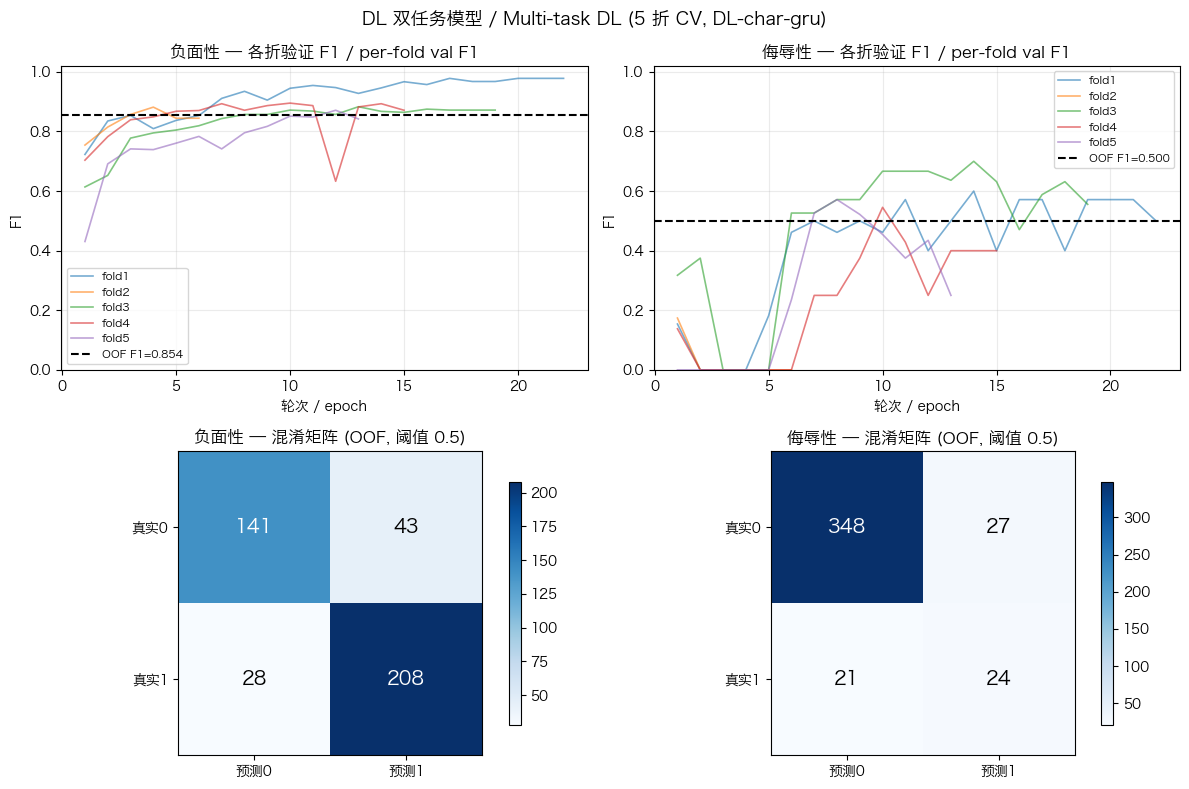

图已保存 / figure: /Users/Edward/Github/LLM-Sentiment-Analysis/Data/DL/dl_curves.png


In [11]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 中文字体：按可用性择一 / pick an available CJK font
_have = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["PingFang SC", "Hiragino Sans GB", "Heiti SC", "Songti SC",
              "Arial Unicode MS", "STHeiti", "SimHei",
              "Noto Sans CJK SC", "Microsoft YaHei", "Noto Sans SC"]:
    if _name in _have:
        plt.rcParams["font.sans-serif"] = [_name]
        print(f"使用中文字体 / CJK font: {_name}")
        break
else:
    print("警告：未找到中文字体，图中中文可能显示为方框")
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for k, d in enumerate(DIMS):
    ax = axes[0][k]
    for rec in fold_records:
        ax.plot(rec["hist"]["epoch"], rec["hist"]["f1_neg" if k == 0 else "f1_ins"],
                alpha=0.6, lw=1.2, label=f"fold{rec['fold']}")
    f1_oof = f1_score(y_all[:, k], (oof[:, k] >= 0.5).astype(int), zero_division=0)
    ax.axhline(f1_oof, color="k", ls="--", lw=1.5, label=f"OOF F1={f1_oof:.3f}")
    ax.set_title(f"{d} — 各折验证 F1 / per-fold val F1", fontsize=12)
    ax.set_xlabel("轮次 / epoch"); ax.set_ylabel("F1")
    ax.set_ylim(0, 1.02); ax.grid(alpha=0.25); ax.legend(fontsize=8)

    ax = axes[1][k]
    cm = confusion_matrix(y_all[:, k], (oof[:, k] >= 0.5).astype(int), labels=[0, 1])
    im = ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["预测0", "预测1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["真实0", "真实1"])
    ax.set_title(f"{d} — 混淆矩阵 (OOF, 阈值 0.5)", fontsize=12)
    fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle(f"DL 双任务模型 / Multi-task DL ({N_FOLDS} 折 CV, {tag})", fontsize=13)
fig.tight_layout()
fig.savefig(OUT_DIR / "dl_curves.png", dpi=150)
plt.show()
print(f"图已保存 / figure: {OUT_DIR / 'dl_curves.png'}")

## 十一、导出结果

OOF 预测表的列名与 `Data/ML/ML_predictions.csv` 对齐（`{模型}+负面性` / `{模型}+侮辱性`），
可以直接并进既有的对比流程。

In [12]:
pred_df = df[["类型", "评论", *LABEL_COLS.values()]].copy()
pred_df[f"{tag}+负面性原始"] = (oof[:, 0] >= 0.5).astype(int)
pred_df[f"{tag}+负面性"] = (oof_fix[:, 0] >= 0.5).astype(int)
pred_df[f"{tag}+侮辱性"] = (oof[:, 1] >= 0.5).astype(int)
pred_df[f"{tag}+负面性_prob"] = oof[:, 0].round(4)
pred_df[f"{tag}+侮辱性_prob"] = oof[:, 1].round(4)

fold_csv = fold_df.drop(columns=["hist"]).copy()
col_order = ["fold", "最佳轮次", "负面性_P@0.5", "负面性_R@0.5", "负面性_F1@0.5",
             "负面性_F1@调优", "侮辱性_P@0.5", "侮辱性_R@0.5", "侮辱性_F1@0.5",
             "侮辱性_F1@调优", "阈值_负面性", "阈值_侮辱性", "n_train", "n_val", "耗时秒"]
fold_csv = fold_csv[[c for c in col_order if c in fold_csv.columns]]

files = {
    "DL_predictions.csv": pred_df,
    "dl_metrics_main.csv": main_df,
    "dl_metrics_folds.csv": fold_csv,
    "dl_metrics_by_type.csv": by_type_df,
    "dl_metrics_confusion.csv": conf_df,
    "dl_metrics_baseline.csv": base_df,
    "dl_thresholds.csv": fold_csv[["fold", "阈值_负面性", "阈值_侮辱性"]],
    "dl_compare_routes.csv": comp_df,
}
for name, frame in files.items():
    frame.to_csv(OUT_DIR / name, index=False, encoding="utf-8-sig")

cfg = {
    "config": {"backbone": BACKBONE, "arch": ARCH if BACKBONE == "char" else None,
               "hf_model": HF_MODEL if BACKBONE == "hf" else None,
               "folds": N_FOLDS, "epochs": EPOCHS, "patience": PATIENCE,
               "batch_size": BATCH_SIZE, "lr": LR, "dropout": DROPOUT,
               "emb_dim": EMB_DIM, "hidden_dim": HIDDEN_DIM, "maxlen": MAXLEN,
               "pos_weight": POS_WEIGHT, "focal_gamma": FOCAL_GAMMA,
               "neg_loss_weight": NEG_LOSS_WEIGHT, "select_metric": SELECT_METRIC,
               "threshold_metric": THRESHOLD_METRIC, "seed": SEED},
    "data": {"path": str(DATA_PATH.relative_to(PROJ)), "md5": md5_of(DATA_PATH),
             "n_rows": len(df), "n_unique_texts": n_unique},
    "eval": {"group_by_text": GROUP_BY_TEXT, "hierarchy_fix": HIERARCHY_FIX,
             "n_hierarchy_fixed": n_fixed, "torch": torch.__version__,
             "device": str(DEVICE)},
}
(OUT_DIR / "dl_config.json").write_text(
    json.dumps(cfg, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"已导出到 {OUT_DIR}/")
for name in list(files) + ["dl_config.json", "dl_curves.png"]:
    p = OUT_DIR / name
    if p.exists():
        print(f"  {name:<26s} {p.stat().st_size / 1024:>7.1f} KB")

已导出到 /Users/Edward/Github/LLM-Sentiment-Analysis/Data/DL/
  DL_predictions.csv            50.7 KB
  dl_metrics_main.csv            0.8 KB
  dl_metrics_folds.csv           0.6 KB
  dl_metrics_by_type.csv         0.6 KB
  dl_metrics_confusion.csv       0.1 KB
  dl_metrics_baseline.csv        0.3 KB
  dl_thresholds.csv              0.1 KB
  dl_compare_routes.csv          1.4 KB
  dl_config.json                 0.7 KB
  dl_curves.png                170.4 KB


## 结果解读要点

1. **不要只看 Accuracy**：侮辱性正类占 10.7%，「全判 0」的 Accuracy 就是 0.893——
   这就是 8.2 那张基线表存在的意义。评估一律以 F1 为准。

2. **深度学习在侮辱性上明显超过传统 ML**：字符级网络直接看到「沙币」「歹匕」这类
   字符层替换，而 jieba 分词 + 词级 TF-IDF 会把这些模式切碎，所以 ML 的侮辱性 F1
   只有 0.28~0.35。这是"字符级建模"最直接的证据。

3. **但仍然打不过 LLM**：大模型的侮辱性 F1 在 0.75~0.79。数据量（420 条）是根本约束——
   参数从零学不到足够的语义先验。若要在后续工作中进一步提升，方向是
   `USE_HF=True` 微调中文 RoBERTa（把预训练语义先验搬进来），而不是加深网络。

4. **语气型差评是共同盲区**：无论 ML、DL 还是 LLM，字面全是好话的反讽（"这饭菜的味道，
   门神王爷吃了都连夜逃跑"）都是召回塌陷最严重的一类。这不是模型缺陷，而是任务本身的
   语用难度，也正是本研究对抗样本设计的价值所在。

5. **跨折波动必须报告**：45 个正类分到 5 折，每折只有 ~9 条。侮辱性 F1 的跨折 std
   在 0.10 左右，Bootstrap CI 宽度也不小。正文只能写"区间"，不能写单次数字。

6. **对随机种子高度敏感 —— 必须做多种子重复**：同一个脚本、同样的切分，只改变随机流，
   侮辱性 F1 实测在 **0.486 / 0.552 / 0.595 / 0.608** 之间跳；负面性稳定在 0.853~0.876。
   原因很直接：45 个正类分到 5 折后每折只有 ~9 个，"学不学得会侮辱"很大程度取决于
   每折恰好分到哪几个样本。**只报单一种子的数字是不可接受的**，建议
   `SEED ∈ {42, 7, 2024, 1234, 999}` 各跑一遍，报 mean ± std 与最好/最差，
   并把五组结果放进附录。相对而言负面性的结论是稳健的，可以作主结论。

7. **提示词工程没有显著增益**（见 `llm_metrics.ipynb` 的 McNemar 检验），而深度学习
   带来的提升是量级上的——这个对比本身就是核心结论之一。

### 下一步可做的实验（按性价比排序）

| 实验 | 命令/改动 | 预期 |
|---|---|---|
| 换编码结构 | `ARCH = "cnn"` 或 `"bilstm"` | 看字符 n-gram 是否比字序更有效 |
| 微调预训练模型 | `USE_HF = True`（需能访问 HF） | 侮辱性 F1 有望进入 0.7~0.8 区间 |
| 去掉分组切分 | `GROUP_BY_TEXT = False` | 指标会略微上升（同文泄漏），用于量化泄漏幅度 |
| 关闭层级修正 | `HIERARCHY_FIX = False` | 检查侮辱性预测与负面性预测的一致性 |
| 阈值-召回权衡 | `THRESHOLD_METRIC = "f2"` | 若业务更怕漏判侮辱，用 F2 偏向召回 |
| 多随机种子重复 | 改 `SEED` 跑 5 次 | 给出"种子级"波动，比折间波动更保守 |